# Bank Customer Churn Prediction — Complete ML Workflow

**Course:** CSE 4101 — Introduction to Machine Learning · **Assignment:** Practical Lab Assignment 10 (individual)
**Problem:** supervised binary classification — predict whether a customer leaves the bank (`Exited = 1`).
**Dataset:** Kaggle _Bank Customer Churn Prediction (2026)_, labeled `train.csv` (+ unlabeled `test.csv` for Task 10).

## Objectives

1. Load/inspect data (Task 1) and explore churn patterns (Task 2).
2. Exclude identifiers, investigate leakage (Task 3).
3. Stratified 70/15/15 split (Task 4) and leakage-free preprocessing pipelines (Task 5).
4. Compare Logistic Regression, Random Forest, Gradient Boosting (Task 6); tune ≥2 hyperparameters each (Task 7).
5. Diagnose train vs. validation behaviour (Task 8); evaluate **once** on the internal test set (Task 9).
6. Predict five unlabeled competition rows and state limitations (Task 10).

## Data roles (never mixed)

| Split                  | Role                                                                                    |
| ---------------------- | --------------------------------------------------------------------------------------- |
| Training (70%)         | fit preprocessing and model parameters; cross-validation folds are drawn only from here |
| Validation (15%)       | compare models, choose the final model and decision threshold                           |
| Internal test (15%)    | touched exactly once, in Task 9                                                         |
| Competition `test.csv` | inference only (no labels)                                                              |

Detailed explanations live in the `docs/` folder.


## 1. Environment setup and reproducibility


In [1]:
import os, sys, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42          # single seed used for splits, models and CV
THRESHOLD_DEFAULT = 0.5    # documented starting decision threshold for Task 6
TARGET = "Exited"          # positive class = 1 (customer churned)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
print("Python      :", platform.python_version())
for m in (np, pd, matplotlib, sns, sklearn):
    print(f"{m.__name__:<12}:", m.__version__)

Python      : 3.13.16
numpy       : 2.1.3
pandas      : 2.2.3
matplotlib  : 3.10.0
seaborn     : 0.13.2
sklearn     : 1.6.1


## 2. Google Drive mounting and data loading

In Colab the notebook mounts Drive and reads `/content/drive/MyDrive/Customer Churn Prediction/train.csv` (default).
Outside Colab (local development only) it falls back to `data/train.csv`. The loader never silently switches to any other file.


In [2]:
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/Customer Churn Prediction")
else:
    # LOCAL DEVELOPMENT FALLBACK ONLY: run from the project root or from notebooks/
    root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
    DATA_DIR = root / "data"
    print("Not running in Colab -> using local fallback folder:", DATA_DIR)

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"     # optional, unlabeled competition file (Task 10)

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"train.csv not found at: {TRAIN_PATH}\n"
        "Place train.csv in Google Drive at 'MyDrive/Customer Churn Prediction/train.csv' "
        "(download it from https://www.kaggle.com/competitions/bank-customer-churn-prediction-2026/data), "
        "then re-run this cell.")

df = pd.read_csv(TRAIN_PATH)
print("Loaded file :", TRAIN_PATH)
print("Shape       :", df.shape)
print("Columns     :", list(df.columns))

# --- schema sanity checks ---
assert not df.empty, "train.csv is empty"
assert df.columns.is_unique, f"Duplicate column names: {df.columns[df.columns.duplicated()].tolist()}"
assert TARGET in df.columns, f"Target column '{TARGET}' missing. Found: {list(df.columns)}"
assert df[TARGET].notna().all(), "Target contains missing values"
assert set(df[TARGET].unique()) <= {0, 1}, f"Unexpected target values: {df[TARGET].unique()}"
df[TARGET] = df[TARGET].astype(int)   # stored as 0.0/1.0 floats in the CSV
df.head()

Mounted at /content/drive
Loaded file : /content/drive/MyDrive/Customer Churn Prediction/train.csv
Shape       : (15000, 14)
Columns     : ['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15653595.0,Ch'en,565.0,France,Male,41.0,4.0,0.0,2.0,1.0,1.0,74580.80,0
1,1,15579433.0,Tsao,594.0,France,Male,31.0,5.0,0.0,2.0,1.0,0.0,167984.61,0
2,2,15611579.0,Oluchi,710.0,Spain,Male,48.0,0.0,155962.0,1.0,1.0,0.0,144870.28,1
3,3,15785559.0,L?,693.0,France,Male,31.0,5.0,0.0,2.0,0.0,1.0,198256.15,0
4,4,15792453.0,Ijendu,574.0,Spain,Female,26.0,2.0,0.0,2.0,0.0,1.0,88890.75,0


## 3. Task 1 — Initial inspection


In [3]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype").join(df.nunique().rename("n_unique")).join(df.isna().sum().rename("n_missing")))
print("Duplicate rows (all columns):", df.duplicated().sum())

counts = df[TARGET].value_counts().sort_index()
dist = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)})
dist.index.name = TARGET
display(dist)

num_cols_all = df.select_dtypes(include="number").columns.drop(TARGET).tolist()
cat_cols_all = df.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns    :", num_cols_all)
print("Categorical columns:", cat_cols_all)

# Potential identifiers: name contains 'id' or many distinct values relative to rows
n = len(df)
id_candidates = {c: df[c].nunique() for c in df.columns if c != TARGET
                 and (df[c].nunique() / n > 0.3 or "id" in c.lower())}
print("Potential identifier-like columns (name contains 'id' or >30% unique):", id_candidates)

minority_share = dist["percent"].min()
print(f"\nObservation: {int(counts[1])} of {n} customers ({counts[1]/n:.1%}) have {TARGET}=1. "
      + ("The classes are clearly imbalanced, so accuracy alone would be misleading."
         if minority_share < 35 else "The classes are roughly balanced."))
display(df.describe().T.round(2))

Shape: (15000, 14)


,dtype,n_unique,n_missing
id,int64,15000,0
CustomerId,float64,6349,0
Surname,object,778,0
CreditScore,float64,371,0
Geography,object,3,0
Gender,object,2,0
Age,float64,55,0
Tenure,float64,11,0
Balance,float64,3302,0
NumOfProducts,float64,4,0


Duplicate rows (all columns): 0


,count,percent
Exited,,
0,11954,79.69
1,3046,20.31


Numeric columns    : ['id', 'CustomerId', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical columns: ['Surname', 'Geography', 'Gender']
Potential identifier-like columns (name contains 'id' or >30% unique): {'id': 15000, 'CustomerId': 6349, 'EstimatedSalary': 6152}

Observation: 3046 of 15000 customers (20.3%) have Exited=1. The classes are clearly imbalanced, so accuracy alone would be misleading.


,count,mean,std,min,25%,50%,75%,max
id,15000.0,7499.50,4330.27,0.00,3749.75,7499.50,11249.25,1.499900e+04
CustomerId,15000.0,15702031.99,1150399.28,15565701.00,15634245.00,15690164.00,15757911.00,1.563167e+08
CreditScore,15000.0,659.25,72.34,431.00,604.00,662.00,709.00,8.500000e+02
Age,15000.0,37.78,8.15,18.00,32.00,37.00,42.00,7.400000e+01
Tenure,15000.0,5.06,2.80,0.00,3.00,5.00,7.00,1.000000e+01
Balance,15000.0,42625.35,59542.06,0.00,0.00,0.00,109161.64,1.879115e+05
NumOfProducts,15000.0,1.59,0.53,1.00,1.00,2.00,2.00,4.000000e+00
HasCrCard,15000.0,0.78,0.41,0.00,1.00,1.00,1.00,1.000000e+00
IsActiveMember,15000.0,0.49,0.50,0.00,0.00,0.00,1.00,1.000000e+00
EstimatedSalary,15000.0,117818.15,46545.07,11.58,82855.88,122964.18,156678.14,1.387001e+06


## 4. Task 2 — Exploratory data analysis

Churn rate = mean of the 0/1 target inside a group (shown as %). Group sizes are shown because small groups give unreliable rates. Differences are associations, not causes.


In [4]:
def churn_rate_table(frame, by):
    g = frame.groupby(by, observed=True)[TARGET].agg(n="size", churn_rate="mean")
    g["churn_rate_%"] = (g["churn_rate"] * 100).round(1)
    return g.drop(columns="churn_rate")

AGE_BINS = [17, 30, 40, 50, 60, 100]          # (17,30], (30,40], ... documented bin edges
tables = {
    "Geography": churn_rate_table(df, "Geography"),
    "Gender": churn_rate_table(df, "Gender"),
    "Age group": churn_rate_table(df.assign(**{"Age group": pd.cut(df["Age"], bins=AGE_BINS)}), "Age group"),
    "Tenure": churn_rate_table(df, "Tenure"),
    "NumOfProducts": churn_rate_table(df, "NumOfProducts"),
    "IsActiveMember": churn_rate_table(df, "IsActiveMember"),
}
print("Age bins:", AGE_BINS, "| min/max Age in data:", df.Age.min(), df.Age.max())
for k, t in tables.items():
    print(f"\n--- churn by {k} ---"); display(t)

Age bins: [17, 30, 40, 50, 60, 100] | min/max Age in data: 18.0 74.0

--- churn by Geography ---


,n,churn_rate_%
Geography,,
France,8950,15.9
Germany,2754,39.6
Spain,3296,16.3



--- churn by Gender ---


,n,churn_rate_%
Gender,,
Female,6559,28.6
Male,8441,13.9



--- churn by Age group ---


...

,n,churn_rate_%
Tenure,,
0.0,437,29.1
1.0,1505,27.0
2.0,1604,17.6
3.0,1470,19.0
4.0,1623,22.2
5.0,1580,21.0
6.0,1497,18.1
7.0,1564,16.1
8.0,1625,20.1



--- churn by NumOfProducts ---


,n,churn_rate_%
NumOfProducts,,
1.0,6377,38.8
2.0,8405,4.4
3.0,186,94.6
4.0,32,96.9



--- churn by IsActiveMember ---


,n,churn_rate_%
IsActiveMember,,
0.0,7616,28.0
1.0,7384,12.4


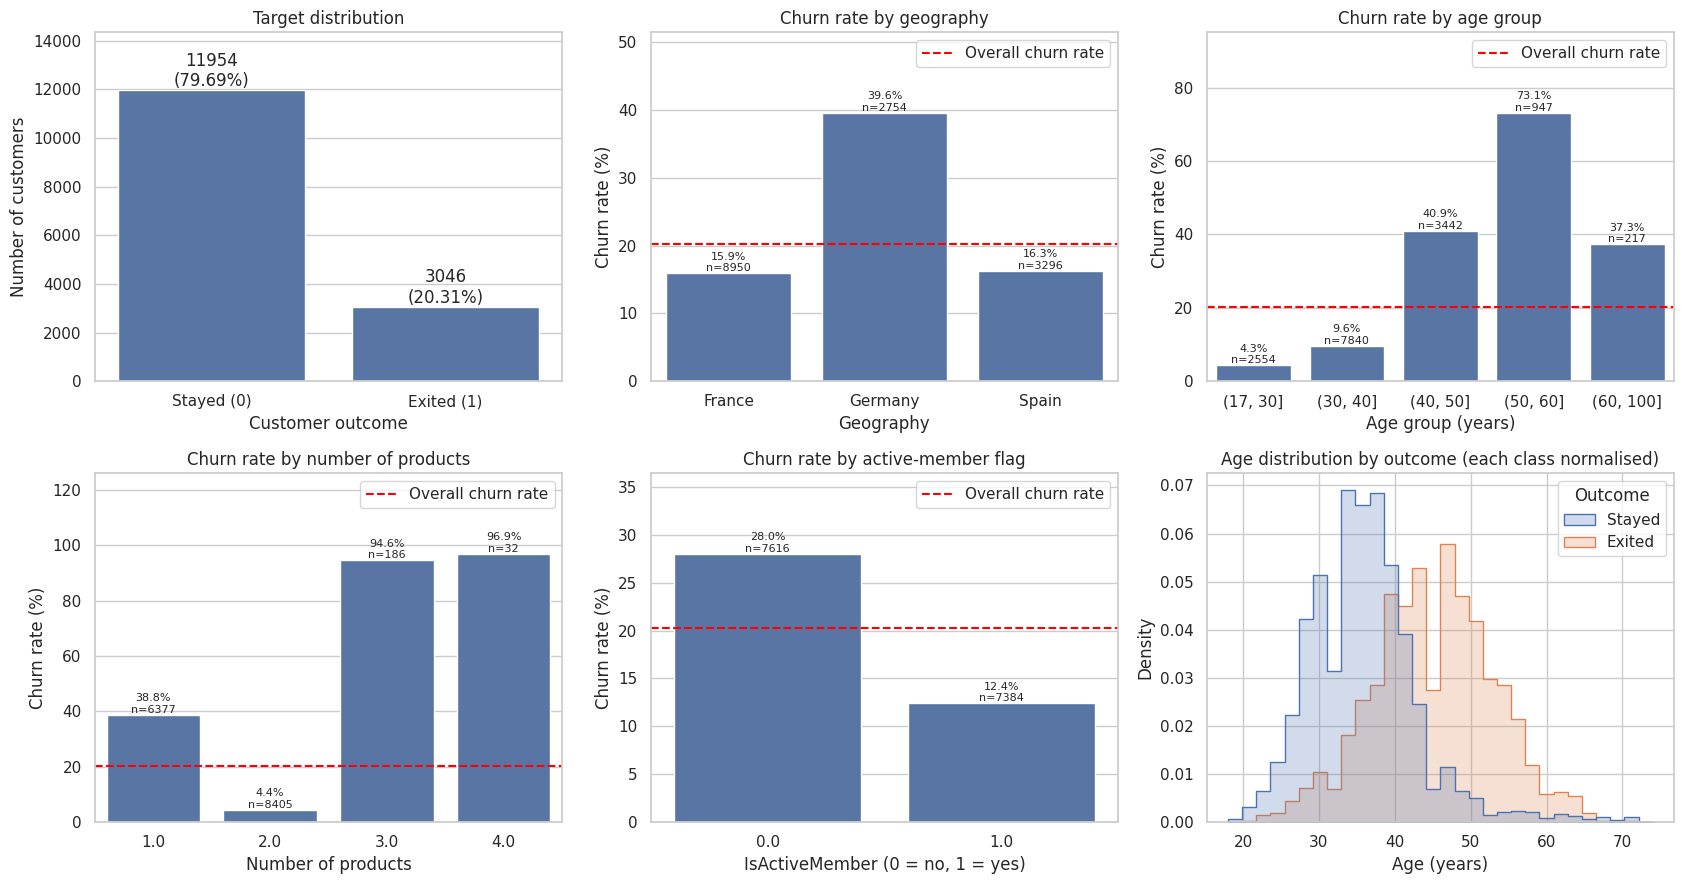

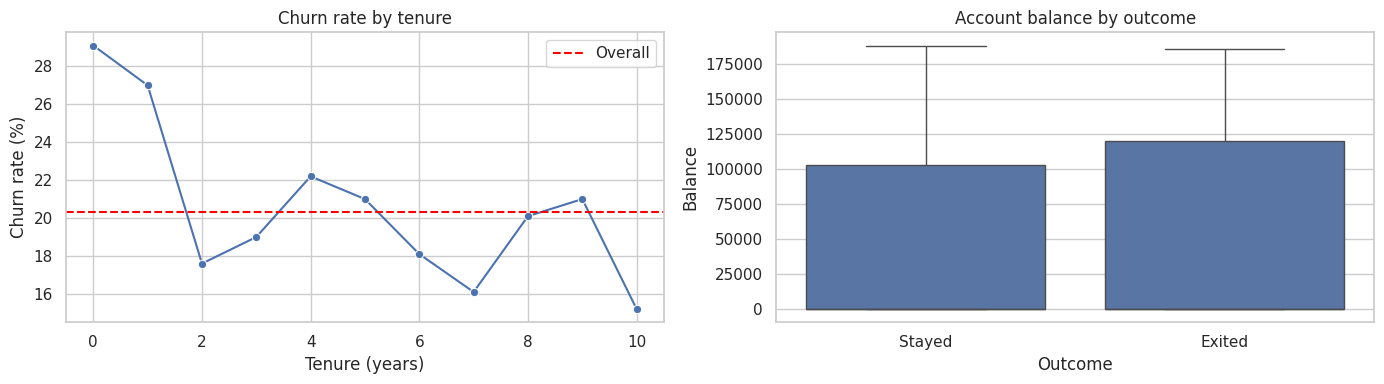

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
overall = df[TARGET].mean() * 100

# Plot 1: target distribution
ax = axes[0, 0]
labels = ["Stayed (0)", "Exited (1)"]
sns.barplot(x=labels, y=dist["count"].values, ax=ax, color="#4C72B0")
for i, (c, p) in enumerate(zip(dist["count"], dist["percent"])): ax.text(i, c, f"{c}\n({p}%)", ha="center", va="bottom")
ax.set_title("Target distribution"); ax.set_xlabel("Customer outcome"); ax.set_ylabel("Number of customers")
ax.set_ylim(0, dist["count"].max() * 1.2)

def rate_bar(ax, key, title, xlabel):
    t = tables[key].reset_index()
    t[t.columns[0]] = t[t.columns[0]].astype(str)
    sns.barplot(data=t, x=t.columns[0], y="churn_rate_%", ax=ax, color="#4C72B0")
    for i, (r, n_) in enumerate(zip(t["churn_rate_%"], t["n"])): ax.text(i, r, f"{r}%\nn={n_}", ha="center", va="bottom", fontsize=8)
    ax.axhline(overall, color="red", ls="--", label="Overall churn rate")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Churn rate (%)"); ax.legend()
    ax.set_ylim(0, t["churn_rate_%"].max() * 1.3)

rate_bar(axes[0, 1], "Geography", "Churn rate by geography", "Geography")
rate_bar(axes[0, 2], "Age group", "Churn rate by age group", "Age group (years)")
rate_bar(axes[1, 0], "NumOfProducts", "Churn rate by number of products", "Number of products")
rate_bar(axes[1, 1], "IsActiveMember", "Churn rate by active-member flag", "IsActiveMember (0 = no, 1 = yes)")

# Plot 6: Age distribution by outcome
ax = axes[1, 2]
sns.histplot(data=df.assign(Outcome=df[TARGET].map({0: "Stayed", 1: "Exited"})), x="Age", hue="Outcome",
             bins=30, stat="density", common_norm=False, element="step", ax=ax)
ax.set_title("Age distribution by outcome (each class normalised)"); ax.set_xlabel("Age (years)"); ax.set_ylabel("Density")
plt.tight_layout(); plt.show()

# Extra: tenure and balance
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
t = tables["Tenure"].reset_index()
sns.lineplot(data=t, x="Tenure", y="churn_rate_%", marker="o", ax=axes[0]); axes[0].axhline(overall, color="red", ls="--", label="Overall")
axes[0].set_title("Churn rate by tenure"); axes[0].set_xlabel("Tenure (years)"); axes[0].set_ylabel("Churn rate (%)"); axes[0].legend()
sns.boxplot(data=df.assign(Outcome=df[TARGET].map({0: "Stayed", 1: "Exited"})), x="Outcome", y="Balance", ax=axes[1])
axes[1].set_title("Account balance by outcome"); axes[1].set_xlabel("Outcome"); axes[1].set_ylabel("Balance")
plt.tight_layout(); plt.show()

In [6]:
# Observations generated from the computed tables (not written in advance)
g = tables["Geography"]; a = tables["Age group"]; p = tables["NumOfProducts"]; act = tables["IsActiveMember"]; ten = tables["Tenure"]
print(f"1. Geography: highest churn in {g['churn_rate_%'].idxmax()} ({g['churn_rate_%'].max()}%), lowest in "
      f"{g['churn_rate_%'].idxmin()} ({g['churn_rate_%'].min()}%); overall rate is {overall:.1f}%.")
print(f"2. Age: the {a['churn_rate_%'].idxmax()} group churns most ({a['churn_rate_%'].max()}%, n={a.loc[a['churn_rate_%'].idxmax(),'n']}); "
      f"the {a['churn_rate_%'].idxmin()} group least ({a['churn_rate_%'].min()}%).")
print(f"3. Products: churn ranges from {p['churn_rate_%'].min()}% ({p['churn_rate_%'].idxmin()} products) to "
      f"{p['churn_rate_%'].max()}% ({p['churn_rate_%'].idxmax()} products, n={p.loc[p['churn_rate_%'].idxmax(),'n']}); check n before trusting extremes.")
print(f"4. Activity: IsActiveMember=0 -> {act.loc[0,'churn_rate_%']}%, IsActiveMember=1 -> {act.loc[1,'churn_rate_%']}%.")
print(f"5. Tenure: churn rate by tenure year spans {ten['churn_rate_%'].min()}%-{ten['churn_rate_%'].max()}% (see line plot; smaller n at the ends).")
print(f"6. Balance: mean Balance of churners = {df.loc[df[TARGET]==1,'Balance'].mean():,.0f} vs non-churners = {df.loc[df[TARGET]==0,'Balance'].mean():,.0f} (medians: {df.loc[df[TARGET]==1,'Balance'].median():,.0f} / {df.loc[df[TARGET]==0,'Balance'].median():,.0f}); "
      f"{(df.Balance==0).mean():.1%} of customers have zero balance.")
print("Caveat: these are group-level associations in this sample, not causal effects.")

1. Geography: highest churn in Germany (39.6%), lowest in France (15.9%); overall rate is 20.3%.
2. Age: the (50, 60] group churns most (73.1%, n=947); the (17, 30] group least (4.3%).
3. Products: churn ranges from 4.4% (2.0 products) to 96.9% (4.0 products, n=32); check n before trusting extremes.
4. Activity: IsActiveMember=0 -> 28.0%, IsActiveMember=1 -> 12.4%.
5. Tenure: churn rate by tenure year spans 15.2%-29.1% (see line plot; smaller n at the ends).
6. Balance: mean Balance of churners = 58,596 vs non-churners = 38,556 (medians: 0 / 0); 64.9% of customers have zero balance.
Caveat: these are group-level associations in this sample, not causal effects.


## 5. Task 3 — Identifier exclusion and target-leakage review

Every column gets an explicit decision. The original `df` is preserved; a separate modelling feature set is built.


In [7]:
audit = pd.DataFrame([
    ("id", "EXCLUDE", "Row identifier (unique per row); carries no generalisable customer information and could let flexible models memorise rows."),
    ("CustomerId", "EXCLUDE", "Customer identifier. It repeats across rows (see check below), so it is not a unique row key, but its numeric value is an arbitrary label, not a behavioural attribute."),
    ("Surname", "EXCLUDE", "Free-text name with many distinct values; an arbitrary label rather than a legitimate predictor, and using names raises fairness/privacy concerns."),
    (TARGET, "TARGET (y only)", "The outcome to predict; must never be part of X."),
] + [(c, "KEEP", "Customer attribute/behaviour assumed known before the churn outcome; no evidence of leakage (see checks).")
     for c in df.columns if c not in ("id", "CustomerId", "Surname", TARGET)],
    columns=["column", "decision", "reason"])
display(audit)

# Evidence checks (leakage is a risk assessment, not proven by correlation alone)
print("CustomerId: unique =", df.CustomerId.nunique(), "of", len(df), "rows ->",
      f"{(df.CustomerId.duplicated(keep=False)).sum()} rows share a CustomerId with another row.")
print("'id' is a sequential row index?", bool((df['id'].diff().dropna() == 1).all()))
kept = [c for c in df.columns if c not in ("id", "CustomerId", "Surname", TARGET)]
corr = df[kept].select_dtypes("number").corrwith(df[TARGET]).abs().sort_values(ascending=False).round(3)
print("\n|correlation| of numeric kept features with target (a near-1 value would signal leakage):"); display(corr.to_frame("|corr|"))
print("No kept feature is almost a copy of the target. Whether each field is truly available at prediction time cannot be proven from the CSV alone;")
print("this is an assumption to confirm with the bank (e.g. Balance/IsActiveMember measured BEFORE the exit).")

EXCLUDE_COLS = ["id", "CustomerId", "Surname"]
X = df.drop(columns=EXCLUDE_COLS + [TARGET])
y = df[TARGET]
print("\nModelling features:", list(X.columns)); print("X shape:", X.shape, "| y shape:", y.shape)

,column,decision,reason
0,id,EXCLUDE,Row identifier (unique per row); carries no ge...
1,CustomerId,EXCLUDE,Customer identifier. It repeats across rows (s...
2,Surname,EXCLUDE,Free-text name with many distinct values; an a...
3,Exited,TARGET (y only),The outcome to predict; must never be part of X.
4,CreditScore,KEEP,Customer attribute/behaviour assumed known bef...
5,Geography,KEEP,Customer attribute/behaviour assumed known bef...
6,Gender,KEEP,Customer attribute/behaviour assumed known bef...
7,Age,KEEP,Customer attribute/behaviour assumed known bef...
8,Tenure,KEEP,Customer attribute/behaviour assumed known bef...
9,Balance,KEEP,Customer attribute/behaviour assumed known bef...


CustomerId: unique = 6349 of 15000 rows -> 12097 rows share a CustomerId with another row.
'id' is a sequential row index? True

|correlation| of numeric kept features with target (a near-1 value would signal leakage):


,|corr|
Age,0.452
NumOfProducts,0.311
IsActiveMember,0.194
Balance,0.135
Tenure,0.043
CreditScore,0.037
EstimatedSalary,0.012
HasCrCard,0.009


No kept feature is almost a copy of the target. Whether each field is truly available at prediction time cannot be proven from the CSV alone;
this is an assumption to confirm with the bank (e.g. Balance/IsActiveMember measured BEFORE the exit).

Modelling features: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
X shape: (15000, 10) | y shape: (15000,)


## 6. Task 4 — Stratified 70 / 15 / 15 split

Two stages, both stratified on `Exited` with the same seed. **Rows are split before any imputer, encoder, scaler or model is fitted.**
Stratification keeps the churn share nearly identical in every subset, which matters because churners are the minority.


,rows,share_of_data_%,churners,churn_rate_%
train (70%),10500,70.0,2132,20.30
validation (15%),2250,15.0,457,20.31
internal test (15%),2250,15.0,457,20.31


Checks passed: splits are disjoint, complete and feature/label rows are aligned.


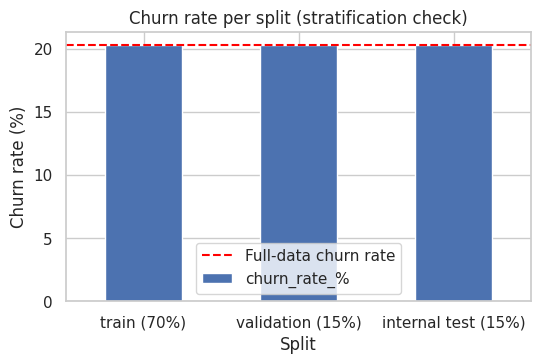

The internal test split (X_test, y_test) is NOT used again until Task 9.


In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)
# naming: X_val/y_val = VALIDATION split; X_test/y_test = INTERNAL TEST split (untouched until Task 9)

split_table = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "share_of_data_%": [round(len(s) / len(y) * 100, 2) for s in (y_train, y_val, y_test)],
    "churners": [int(s.sum()) for s in (y_train, y_val, y_test)],
    "churn_rate_%": [round(s.mean() * 100, 2) for s in (y_train, y_val, y_test)],
}, index=["train (70%)", "validation (15%)", "internal test (15%)"])
display(split_table)
assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index)) and not (set(X_val.index) & set(X_test.index))
assert (X_train.index == y_train.index).all() and (X_val.index == y_val.index).all() and (X_test.index == y_test.index).all()
print("Checks passed: splits are disjoint, complete and feature/label rows are aligned.")

ax = split_table["churn_rate_%"].plot(kind="bar", figsize=(6, 3.5), color="#4C72B0", rot=0)
ax.axhline(y.mean() * 100, color="red", ls="--", label="Full-data churn rate")
ax.set_title("Churn rate per split (stratification check)"); ax.set_xlabel("Split"); ax.set_ylabel("Churn rate (%)"); ax.legend(); plt.show()
print("The internal test split (X_test, y_test) is NOT used again until Task 9.")

## 7. Task 5 — Leakage-free preprocessing with `ColumnTransformer` + `Pipeline`

| Feature type | Steps                                                                             |
| ------------ | --------------------------------------------------------------------------------- |
| Numeric      | `SimpleImputer(median)` → `StandardScaler` (scaling only for Logistic Regression) |
| Categorical  | `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore")`         |

Binary 0/1 flags (`HasCrCard`, `IsActiveMember`) are stored as numbers, so they are treated as numeric columns.
Tree models do not need scaling, so their preprocessor omits `StandardScaler`. Because the preprocessor is a step **inside** each Pipeline,
`fit` on the pipeline (or inside CV) fits imputer/encoder/scaler on the training rows of that call only.


In [9]:
num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric features    :", num_features)
print("Categorical features:", cat_features)
print("Missing values in X_train:", int(X_train.isna().sum().sum()), "(imputers are kept so the pipeline is robust if data with gaps arrives)")

def make_preprocessor(scale_numeric):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
    ])

def make_pipeline(model, scale_numeric):
    return Pipeline([("preprocess", make_preprocessor(scale_numeric)), ("model", model)])

# --- verification that held-out rows do not influence fitting ---
demo = make_preprocessor(scale_numeric=True).fit(X_train)            # fit on TRAIN only
num_pipe = demo.named_transformers_["num"]
check = pd.DataFrame({
    "median learned (train only)": num_pipe["imputer"].statistics_,
    "median of full X (would leak)": X[num_features].median().values,
    "scaler mean (train only)": num_pipe["scaler"].mean_,
    "full-data mean (would leak)": X[num_features].mean().values,
}, index=num_features)
display(check)
assert np.allclose(num_pipe["scaler"].mean_, X_train[num_features].mean().values)
assert np.allclose(num_pipe["imputer"].statistics_, X_train[num_features].median().values)
print("Verified: learned statistics equal training-split statistics (they differ slightly from full-data statistics).")
print("One-hot categories learned from training data:", {c: list(v) for c, v in zip(cat_features, demo.named_transformers_['cat']['onehot'].categories_)})
Xt = demo.transform(X_val)     # transform only: validation rows reuse the training-fitted statistics
print("Transformed validation shape:", Xt.shape, "| output feature names:", list(demo.get_feature_names_out()))

# unseen category check: a never-seen Geography should become all-zero one-hot, not crash
probe = X_val.iloc[:1].copy(); probe["Geography"] = "Atlantis"
print("Unseen-category probe encoded without error ->", demo.transform(probe).shape)

Numeric features    : ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features: ['Geography', 'Gender']
Missing values in X_train: 0 (imputers are kept so the pipeline is robust if data with gaps arrives)


,median learned (train only),median of full X (would leak),scaler mean (train only),full-data mean (would leak)
CreditScore,661.000,662.00,658.746190,659.254333
Age,37.000,37.00,37.704286,37.776133
Tenure,5.000,5.00,5.060190,5.055533
Balance,0.000,0.00,42506.146975,42625.348176
NumOfProducts,2.000,2.00,1.590952,1.591533
HasCrCard,1.000,1.00,0.783714,0.779800
IsActiveMember,0.000,0.00,0.489905,0.492267
EstimatedSalary,122929.615,122964.18,117845.865680,117818.151371


Verified: learned statistics equal training-split statistics (they differ slightly from full-data statistics).
One-hot categories learned from training data: {'Geography': ['France', 'Germany', 'Spain'], 'Gender': ['Female', 'Male']}
Transformed validation shape: (2250, 13) | output feature names: ['num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__HasCrCard', 'num__IsActiveMember', 'num__EstimatedSalary', 'cat__Geography_France', 'cat__Geography_Germany', 'cat__Geography_Spain', 'cat__Gender_Female', 'cat__Gender_Male']
Unseen-category probe encoded without error -> (1, 13)


## 8. Task 6 — Baseline comparison of three classifiers

Selection metric chosen **before** comparing: **ROC-AUC on the validation split** (threshold-independent ranking quality, suitable for an imbalanced target).
Recall, F1, precision and accuracy are reported at the fixed threshold 0.5; the positive class is `Exited = 1`. No class-imbalance remedy is applied in the baselines.


In [10]:
def safe_roc_auc(y_true, scores):
    # ROC-AUC is undefined when only one class is present -> report NaN instead of crashing
    return roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else float("nan")

def evaluate(pipe, X_, y_, threshold=THRESHOLD_DEFAULT):
    proba = pipe.predict_proba(X_)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred, zero_division=0),
            "F1": f1_score(y_, pred, zero_division=0),
            "ROC-AUC": safe_roc_auc(y_, proba)}

baseline_models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), scale_numeric=True),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1), scale_numeric=False),
    "Gradient Boosting": make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE), scale_numeric=False),
}
rows = {}
for name, pipe in baseline_models.items():
    pipe.fit(X_train, y_train)                    # training split ONLY
    rows[name] = evaluate(pipe, X_val, y_val)     # evaluated on validation
baseline_results = pd.DataFrame(rows).T.round(4)
print("Baseline validation results (threshold = 0.5):")
display(baseline_results.sort_values("ROC-AUC", ascending=False))

print("Recorded configurations:")
for name, pipe in baseline_models.items():
    print(f"  {name}: {pipe.named_steps['model'].get_params()}")
best_base = baseline_results["ROC-AUC"].idxmax()
print(f"\nHighest validation ROC-AUC among baselines: {best_base} ({baseline_results.loc[best_base,'ROC-AUC']:.4f}).")
print("Lowest recall:", baseline_results['Recall'].idxmin(), f"({baseline_results['Recall'].min():.4f}); churners are {y.mean():.1%} of the data.")

Baseline validation results (threshold = 0.5):


,Accuracy,Precision,Recall,F1,ROC-AUC
Gradient Boosting,0.8978,0.7963,0.6674,0.7262,0.9288
Random Forest,0.8831,0.7487,0.6389,0.6895,0.9137
Logistic Regression,0.8729,0.7568,0.5514,0.6380,0.8760


Recorded configurations:
  Logistic Regression: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
  Random Forest: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
  Gradient Boosting: {'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, '

**Model families.** Logistic Regression learns one weight per (scaled/one-hot) feature and passes the weighted sum through a sigmoid — a linear decision boundary that is fast and interpretable.
Random Forest averages many deep decision trees trained on bootstrap samples with random feature subsets (variance reduction, captures non-linearity/interactions).
Gradient Boosting builds shallow trees one after another, each correcting the errors of the ensemble so far (bias reduction, sensitive to learning rate and number of trees).


## 9. Task 7 — Hyperparameter tuning (training data + validation evidence)

- `GridSearchCV` with `StratifiedKFold(5, shuffle=True, random_state=42)` runs **inside the 70% training split only**; the preprocessing sits inside the pipeline, so it is refitted in every fold.
- Scoring (and refit rule) = `roc_auc` (same metric chosen up front). Each model is refit on the full training split with its best settings.
- The validation split is then used to compare the tuned candidates. The internal test split is not touched.
- `class_weight` is tuned only for Logistic Regression as a hyperparameter whose benefit is judged by CV evidence (baseline used none).


In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    "Random Forest": {"model__n_estimators": [100, 300], "model__max_depth": [None, 8, 16], "model__min_samples_leaf": [1, 5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3, 4]},
}
searches, tuned = {}, {}
for name, base in baseline_models.items():
    gs = GridSearchCV(base, param_grids[name], scoring="roc_auc", cv=cv, refit=True, n_jobs=-1)
    gs.fit(X_train, y_train)                   # CV folds come only from the training split
    searches[name], tuned[name] = gs, gs.best_estimator_
    print(f"{name}: best CV ROC-AUC = {gs.best_score_:.4f} | best params = {gs.best_params_}")

Logistic Regression: best CV ROC-AUC = 0.8783 | best params = {'model__C': 1, 'model__class_weight': 'balanced'}
Random Forest: best CV ROC-AUC = 0.9292 | best params = {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Gradient Boosting: best CV ROC-AUC = 0.9325 | best params = {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}


,model,params,mean_test_score,std_test_score,rank_test_score
0,Logistic Regression,"{'C': 0.01, 'class_weight': None}",0.8762,0.0108,8
1,Logistic Regression,"{'C': 0.01, 'class_weight': 'balanced'}",0.8773,0.0103,7
2,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.8774,0.0110,4
3,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.8783,0.0104,3
4,Logistic Regression,"{'C': 1, 'class_weight': None}",0.8774,0.0110,5
5,Logistic Regression,"{'C': 1, 'class_weight': 'balanced'}",0.8783,0.0104,1
6,Logistic Regression,"{'C': 10, 'class_weight': None}",0.8774,0.0110,6
7,Logistic Regression,"{'C': 10, 'class_weight': 'balanced'}",0.8783,0.0104,2
8,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9183,0.0083,12
9,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9189,0.0084,10


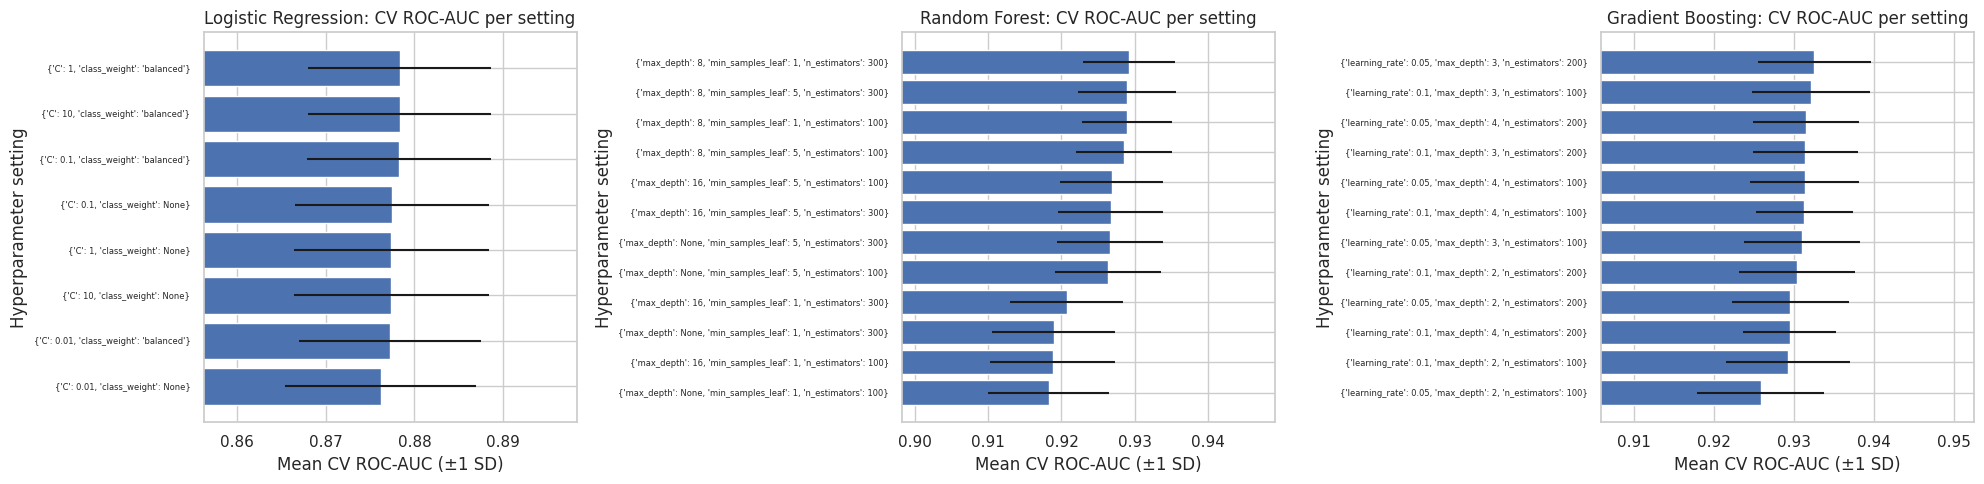

In [12]:
# Every tested setting and its mean CV score
all_cv = []
for name, gs in searches.items():
    r = pd.DataFrame(gs.cv_results_)
    r = r[["params", "mean_test_score", "std_test_score", "rank_test_score"]].assign(model=name)
    all_cv.append(r)
cv_table = pd.concat(all_cv)[["model", "params", "mean_test_score", "std_test_score", "rank_test_score"]]
cv_table["params"] = cv_table["params"].astype(str).str.replace("model__", "", regex=False)
display(cv_table.round(4).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (name, sub) in zip(axes, cv_table.groupby("model", sort=False)):
    s = sub.sort_values("mean_test_score")
    ax.barh(range(len(s)), s["mean_test_score"], xerr=s["std_test_score"], color="#4C72B0")
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s["params"], fontsize=6)
    ax.set_xlim(max(0.5, s["mean_test_score"].min() - 0.02), s["mean_test_score"].max() + 0.02)
    ax.set_title(f"{name}: CV ROC-AUC per setting"); ax.set_xlabel("Mean CV ROC-AUC (±1 SD)"); ax.set_ylabel("Hyperparameter setting")
plt.tight_layout(); plt.show()

In [13]:
# Validation comparison of tuned candidates -> choose the final model (selection metric: validation ROC-AUC)
tuned_val = pd.DataFrame({n: evaluate(p, X_val, y_val) for n, p in tuned.items()}).T.round(4)
print("Tuned models on the VALIDATION split (threshold 0.5):"); display(tuned_val.sort_values("ROC-AUC", ascending=False))
print("Baseline vs tuned validation ROC-AUC:")
display(pd.DataFrame({"baseline": baseline_results["ROC-AUC"], "tuned": tuned_val["ROC-AUC"]}))

final_name = tuned_val["ROC-AUC"].idxmax()
final_model = tuned[final_name]
print(f"\nSELECTED MODEL: {final_name}\nSelected configuration: {searches[final_name].best_params_}")
print(f"Reason: highest validation ROC-AUC ({tuned_val.loc[final_name,'ROC-AUC']:.4f}) among the three tuned candidates; "
      f"its CV ROC-AUC on the training split was {searches[final_name].best_score_:.4f}.")

Tuned models on the VALIDATION split (threshold 0.5):


,Accuracy,Precision,Recall,F1,ROC-AUC
Gradient Boosting,0.8960,0.7911,0.6630,0.7214,0.9283
Random Forest,0.8938,0.8187,0.6127,0.7009,0.9256
Logistic Regression,0.8133,0.5268,0.7965,0.6341,0.8783


Baseline vs tuned validation ROC-AUC:


,baseline,tuned
Logistic Regression,0.8760,0.8783
Random Forest,0.9137,0.9256
Gradient Boosting,0.9288,0.9283



SELECTED MODEL: Gradient Boosting
Selected configuration: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Reason: highest validation ROC-AUC (0.9283) among the three tuned candidates; its CV ROC-AUC on the training split was 0.9325.


### Decision threshold (chosen on validation data only)

Recall at 0.5 is typically low when churners are the minority. The threshold that maximises **validation F1** is picked from a grid; the internal test set plays no part.


Chosen threshold (max validation F1): 0.39  (validation F1 = 0.7410; at 0.50 = 0.7214)


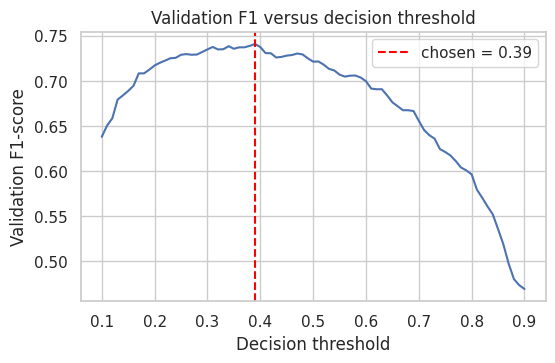

In [14]:
val_proba = final_model.predict_proba(X_val)[:, 1]
thr_grid = np.round(np.arange(0.10, 0.91, 0.01), 2)
thr_f1 = np.array([f1_score(y_val, (val_proba >= t).astype(int), zero_division=0) for t in thr_grid])
FINAL_THRESHOLD = float(thr_grid[thr_f1.argmax()])
f1_at_05 = thr_f1[list(thr_grid).index(0.5)]
print(f"Chosen threshold (max validation F1): {FINAL_THRESHOLD:.2f}  (validation F1 = {thr_f1.max():.4f}; at 0.50 = {f1_at_05:.4f})")
plt.figure(figsize=(6, 3.5)); plt.plot(thr_grid, thr_f1); plt.axvline(FINAL_THRESHOLD, color="red", ls="--", label=f"chosen = {FINAL_THRESHOLD:.2f}")
plt.title("Validation F1 versus decision threshold"); plt.xlabel("Decision threshold"); plt.ylabel("Validation F1-score"); plt.legend(); plt.show()

## 10. Task 8 — Training vs. validation (selected model)

Same model, same positive class and the same threshold (`FINAL_THRESHOLD`) for both splits; ROC-AUC uses probabilities.


,Training,Validation,Gap (train - val)
Recall,0.7402,0.7418,-0.0016
F1,0.7523,0.7410,0.0113
ROC-AUC,0.9425,0.9283,0.0142


Model: Gradient Boosting | threshold = 0.39


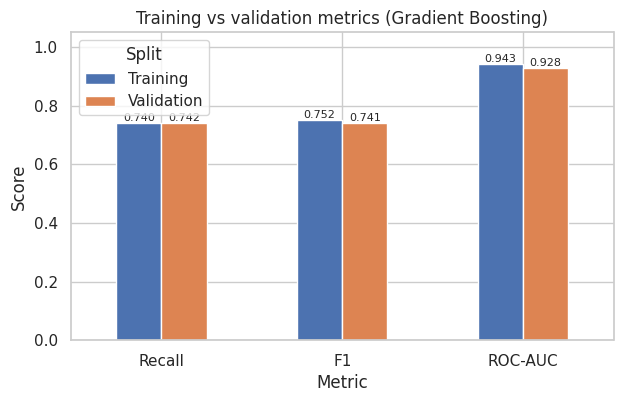

Interpretation: ROC-AUC gap = 0.014. The gap is small, so there is no strong sign of overfitting on this metric.
Low absolute scores on both splits would instead hint at underfitting or limited signal. This is evidence, not proof:
the validation set is finite and its estimates carry sampling noise. Raising recall (fewer missed churners) costs precision (more false alarms).


In [15]:
m_train = evaluate(final_model, X_train, y_train, FINAL_THRESHOLD)
m_val = evaluate(final_model, X_val, y_val, FINAL_THRESHOLD)
diag = pd.DataFrame({"Training": m_train, "Validation": m_val}).loc[["Recall", "F1", "ROC-AUC"]]
diag["Gap (train - val)"] = diag["Training"] - diag["Validation"]
display(diag.round(4))
print(f"Model: {final_name} | threshold = {FINAL_THRESHOLD:.2f}")

ax = diag[["Training", "Validation"]].plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title(f"Training vs validation metrics ({final_name})"); ax.set_xlabel("Metric"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.05); ax.legend(title="Split")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.show()

gap_auc = diag.loc["ROC-AUC", "Gap (train - val)"]
print(f"Interpretation: ROC-AUC gap = {gap_auc:.3f}. "
      + ("A large gap suggests possible overfitting (the model fits training rows better than new rows)."
         if gap_auc > 0.05 else "The gap is small, so there is no strong sign of overfitting on this metric."))
print("Low absolute scores on both splits would instead hint at underfitting or limited signal. This is evidence, not proof:")
print("the validation set is finite and its estimates carry sampling noise. Raising recall (fewer missed churners) costs precision (more false alarms).")

## 11. Task 9 — One-time evaluation on the untouched internal test split

Model, hyperparameters and threshold were all fixed above using training/validation data. This is the only cell that reads `X_test`/`y_test` for scoring.
If anything is changed after viewing these numbers, the test set is no longer a clean final assessment.


FINAL internal-test results: Gradient Boosting, threshold = 0.39, positive class = Exited=1


,Validation,Internal test
Accuracy,0.8947,0.8920
Precision,0.7402,0.7211
Recall,0.7418,0.7637
F1,0.7410,0.7418
ROC-AUC,0.9283,0.9329


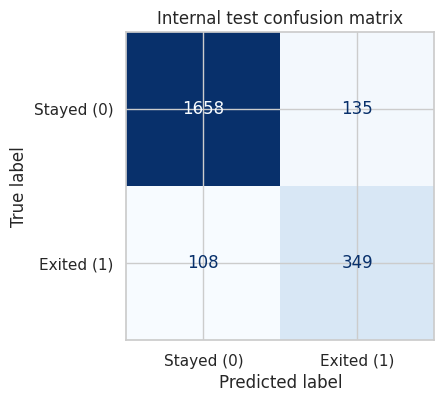

TN=1658: stayed and predicted to stay | FP=135: stayed but flagged as churn (wasted retention offers)
FN=108: churned but missed (lost customers, no action taken) | TP=349: churned and correctly flagged
Test recall 0.764 = TP/(TP+FN) = 349/457; precision 0.721 = TP/(TP+FP) = 349/484.
Validation->test change in ROC-AUC: +0.0045. Differences of this size can arise from sampling noise on 2250 rows.


In [16]:
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= FINAL_THRESHOLD).astype(int)
test_metrics = {"Accuracy": accuracy_score(y_test, test_pred), "Precision": precision_score(y_test, test_pred, zero_division=0),
                "Recall": recall_score(y_test, test_pred, zero_division=0), "F1": f1_score(y_test, test_pred, zero_division=0),
                "ROC-AUC": safe_roc_auc(y_test, test_proba)}
final_table = pd.DataFrame({"Validation": m_val, "Internal test": test_metrics}).round(4)
print(f"FINAL internal-test results: {final_name}, threshold = {FINAL_THRESHOLD:.2f}, positive class = Exited=1"); display(final_table)

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Stayed (0)", "Exited (1)"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Internal test confusion matrix"); ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); plt.show()
print(f"TN={tn}: stayed and predicted to stay | FP={fp}: stayed but flagged as churn (wasted retention offers)")
print(f"FN={fn}: churned but missed (lost customers, no action taken) | TP={tp}: churned and correctly flagged")
print(f"Test recall {test_metrics['Recall']:.3f} = TP/(TP+FN) = {tp}/{tp+fn}; precision {test_metrics['Precision']:.3f} = TP/(TP+FP) = {tp}/{tp+fp}.")
print(f"Validation->test change in ROC-AUC: {test_metrics['ROC-AUC']-m_val['ROC-AUC']:+.4f}. Differences of this size can arise from sampling noise on {len(y_test)} rows.")

## 12. Task 10 — Predictions for five unlabeled competition-test rows

The optional `test.csv` has no `Exited` column, so **no metrics are computed**. The already-fitted `final_model` is only applied (`predict_proba`); nothing is refitted.
Identifiers are kept aside for reporting and removed from model inputs. If the file is missing, this section reports that and the notebook continues.


In [17]:
if not TEST_PATH.exists():
    print(f"Task 10 BLOCKED: competition test file not found at {TEST_PATH}.\n"
          "Download test.csv from the Kaggle competition page and put it next to train.csv "
          "(Drive: MyDrive/Customer Churn Prediction/test.csv), then re-run this cell.")
else:
    comp = pd.read_csv(TEST_PATH)
    print("Loaded:", TEST_PATH, "| shape:", comp.shape, "| columns:", list(comp.columns))
    missing = [c for c in X_train.columns if c not in comp.columns]
    if missing:
        print("Task 10 BLOCKED: competition file lacks required model columns:", missing)
    else:
        assert TARGET not in comp.columns, "Competition file unexpectedly has labels"
        ids = comp[["id"]] if "id" in comp.columns else pd.DataFrame(index=comp.index)
        comp_X = comp[X_train.columns.tolist()]                 # same columns/order as training features
        five = comp_X.head(5)
        proba5 = final_model.predict_proba(five)[:, 1]
        out = ids.head(5).copy()
        out["predicted_label"] = (proba5 >= FINAL_THRESHOLD).astype(int)
        out["churn_probability"] = proba5.round(4)
        display(out.reset_index(drop=True))
        print("Probabilities are model estimates, not guarantees and not necessarily calibrated real-world probabilities.")
        print("Unlabeled rows: no accuracy/recall/F1 can be computed for them.")

Loaded: /content/drive/MyDrive/Customer Churn Prediction/test.csv | shape: (10000, 13) | columns: ['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


,id,predicted_label,churn_probability
0,15000,1,0.3948
1,15001,0,0.2863
2,15002,0,0.0436
3,15003,1,0.9094
4,15004,0,0.0213


Probabilities are model estimates, not guarantees and not necessarily calibrated real-world probabilities.
Unlabeled rows: no accuracy/recall/F1 can be computed for them.


## 13. Final conclusions, limitations and reproducibility


In [18]:
print("SUMMARY (all numbers come from the cells above)")
print(f"- Data: {len(df)} labeled rows, churn rate {y.mean():.1%}; split 70/15/15 stratified, seed {RANDOM_STATE}.")
print(f"- Selected model: {final_name} with {searches[final_name].best_params_} (chosen by validation ROC-AUC), threshold {FINAL_THRESHOLD:.2f} (chosen by validation F1).")
print(f"- Validation ROC-AUC {m_val['ROC-AUC']:.4f}, F1 {m_val['F1']:.4f}, Recall {m_val['Recall']:.4f}.")
print(f"- Internal test (one-time) ROC-AUC {test_metrics['ROC-AUC']:.4f}, F1 {test_metrics['F1']:.4f}, Recall {test_metrics['Recall']:.4f}, Precision {test_metrics['Precision']:.4f}.")
print(f"- Train-validation ROC-AUC gap: {gap_auc:+.4f}.")
dup_cust = df.CustomerId.duplicated(keep=False).mean()
print(f"- Unexpected finding: {dup_cust:.1%} of rows share a CustomerId with another row although they are different records; "
      "the same customer may appear in several splits, which could make validation/test scores optimistic.")

SUMMARY (all numbers come from the cells above)
- Data: 15000 labeled rows, churn rate 20.3%; split 70/15/15 stratified, seed 42.
- Selected model: Gradient Boosting with {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200} (chosen by validation ROC-AUC), threshold 0.39 (chosen by validation F1).
- Validation ROC-AUC 0.9283, F1 0.7410, Recall 0.7418.
- Internal test (one-time) ROC-AUC 0.9329, F1 0.7418, Recall 0.7637, Precision 0.7211.
- Train-validation ROC-AUC gap: +0.0142.
- Unexpected finding: 80.6% of rows share a CustomerId with another row although they are different records; the same customer may appear in several splits, which could make validation/test scores optimistic.


### Real-world limitations

1. **Representativeness / changing behaviour:** the model reflects one historical (possibly synthetic, competition-style) sample. Customer behaviour, markets and bank policies change, so performance can degrade over time; monitoring and retraining would be needed.
2. **Calibration and business cost:** predicted probabilities are scores, not guaranteed real-world risks, and were not calibrated. The threshold was chosen by validation F1, which treats false positives and false negatives as equally important; a real bank would weigh retention-offer cost against lost-customer value.
3. **Association, not causation:** patterns such as higher churn in certain geographies or age groups do not explain _why_ customers leave, and using attributes like geography, age or gender in decisions raises fairness concerns that were not audited here.
4. **Possible duplicate customers and unverified feature timing:** repeated `CustomerId` values across splits and the unverified assumption that all features exist before the churn event can inflate apparent performance.

### Reproducibility notes

Seed `RANDOM_STATE = 42` is used for splits, CV and models; package versions are printed at the top. Results can still differ slightly across library versions or hardware.
